<img src="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRHuCwrMl7_P1P9qfrC17WW2nkhg79X25bi0A&s" width="500"/>

## Universidad Iberoamericana

**Facultad de Ingeniería**  
**Ingeniería de Software**  
**Asignatura:** Inteligencia Artificial  
**Actividad 4:** Métodos de aprendizaje no supervisado  
**Tema:** Perfiles de puntualidad ferroviaria con clustering jerárquico  

---

## Problema

El objetivo es descubrir **perfiles de comportamiento de trenes** sin usar una etiqueta de clase.

Se utiliza un solo método no supervisado: **clustering jerárquico aglomerativo con enlace Ward**. Este método es útil porque permite visualizar la estructura de agrupamiento mediante un dendrograma.

## Fuente de datos

Dataset público de Kaggle: **Indian Railways - Delay Dataset** (`rxydenxd/indian-railways-delay-dataset`).

Para esta actividad se construye un perfil por tren a partir de la tabla `combined_delay`.

## 1. Instalación e importación

In [1]:
# ============================================================
# 1. INSTALACIÓN
# ============================================================

# En Colab instala KaggleHub si no está disponible.
# En validación local con DATASET_LOCAL_DIR no se instala nada.
import os
import importlib.util

if os.environ.get("DATASET_LOCAL_DIR") is None and importlib.util.find_spec("kagglehub") is None:
    !pip -q install kagglehub


In [2]:
# ============================================================
# 2. IMPORTACIÓN DE LIBRERÍAS
# ============================================================

from pathlib import Path
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (8, 5)


## 2. Descarga y lectura del dataset

In [3]:
# ============================================================
# 3. CONFIGURACIÓN
# ============================================================

DATASET_HANDLE = "rxydenxd/indian-railways-delay-dataset"
MAX_LECTURA = 500000
MIN_OBSERVACIONES = 20
DATASET_LOCAL = os.environ.get("DATASET_LOCAL_DIR")

OUTPUT_DIR = Path("salidas_actividad4")
OUTPUT_DIR.mkdir(exist_ok=True)


In [4]:
# ============================================================
# 4. FUNCIONES DE APOYO
# ============================================================

def normalizar_columnas(df):
    # Nombres consistentes: minúsculas, sin espacios y con guion bajo.
    df = df.copy()
    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(" ", "_", regex=False)
        .str.replace("-", "_", regex=False)
    )
    return df

def leer_tabla(ruta, nrows=None):
    # Lee CSV o Parquet según el formato del archivo.
    ruta = Path(ruta)
    if ruta.suffix.lower() == ".csv":
        return pd.read_csv(ruta, nrows=nrows, low_memory=False)
    if ruta.suffix.lower() in [".parquet", ".pq"]:
        df_tmp = pd.read_parquet(ruta)
        return df_tmp.head(nrows) if nrows else df_tmp
    raise ValueError(f"Formato no soportado: {ruta}")

def buscar_archivo(carpeta, texto):
    # Busca un archivo del dataset por parte del nombre.
    candidatos = [p for p in Path(carpeta).rglob("*") if p.is_file() and texto in p.stem.lower()]
    if not candidatos:
        raise FileNotFoundError(f"No se encontró archivo con: {texto}")
    return candidatos[0]


In [5]:
# ============================================================
# 5. DESCARGA PÚBLICA DESDE KAGGLE
# ============================================================

if DATASET_LOCAL:
    dataset_path = Path(DATASET_LOCAL)
else:
    import kagglehub
    dataset_path = Path(kagglehub.dataset_download(DATASET_HANDLE))

archivo_delay = buscar_archivo(dataset_path, "combined_delay")
print("Tabla de retrasos:", archivo_delay)


Tabla de retrasos: /mnt/data/ibero_final_packages/fixture_indian_railways/combined_delay.csv


In [6]:
# ============================================================
# 6. LECTURA Y LIMPIEZA
# ============================================================

df = normalizar_columnas(leer_tabla(archivo_delay, MAX_LECTURA))

# Nombres esperados en el dataset.
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["delay"] = pd.to_numeric(df["delay"], errors="coerce")
df["train_no"] = df["train_no"].astype(str).str.strip()

df = df.dropna(subset=["date", "delay", "train_no"]).copy()
df = df[df["delay"] >= 0].copy()

print("Dimensiones:", df.shape)
display(df.head())


Dimensiones: (8000, 4)


,date,train_no,station_name,delay
0,2026-01-05,10077,ST019,22.79
1,2026-01-25,10059,ST005,38.00
2,2026-01-27,10033,ST027,19.80
3,2026-04-23,10060,ST016,0.25
4,2026-01-29,10069,ST011,16.35


## 3. Construcción del perfil por tren

In [7]:
# ============================================================
# 7. PERFIL POR TREN
# ============================================================

# Indicadores binarios para resumir puntualidad y severidad.
df["a_tiempo"] = (df["delay"] <= 15).astype(int)
df["retraso_severo"] = (df["delay"] > 30).astype(int)

# Reducir impacto de valores extremos para el análisis de perfil.
limite_superior = df["delay"].quantile(0.99)
df["delay_limpio"] = df["delay"].clip(upper=limite_superior)

perfil_trenes = (
    df.groupby("train_no")
    .agg(
        retraso_mediano=("delay_limpio", "median"),
        retraso_promedio=("delay_limpio", "mean"),
        retraso_p90=("delay_limpio", lambda x: x.quantile(0.90)),
        desviacion_retraso=("delay_limpio", "std"),
        porcentaje_a_tiempo=("a_tiempo", lambda x: x.mean() * 100),
        porcentaje_retraso_severo=("retraso_severo", lambda x: x.mean() * 100),
        observaciones=("delay_limpio", "count")
    )
    .reset_index()
)

perfil_trenes = perfil_trenes[perfil_trenes["observaciones"] >= MIN_OBSERVACIONES].dropna().copy()

print("Cantidad de trenes analizados:", len(perfil_trenes))
display(perfil_trenes.head())


Cantidad de trenes analizados: 80


,train_no,retraso_mediano,retraso_promedio,retraso_p90,desviacion_retraso,porcentaje_a_tiempo,porcentaje_retraso_severo,observaciones
0,10000,17.440,17.442807,33.231,11.319724,45.614035,14.912281,114
1,10001,24.710,25.759245,39.440,9.303240,12.264151,31.132075,106
2,10002,37.430,37.614539,52.200,11.948488,4.255319,75.886525,141
3,10003,18.010,16.971712,27.540,9.368245,39.639640,8.108108,111
4,10004,23.205,22.462000,36.081,11.801830,30.909091,23.636364,110


## 4. Mini EDA de los perfiles

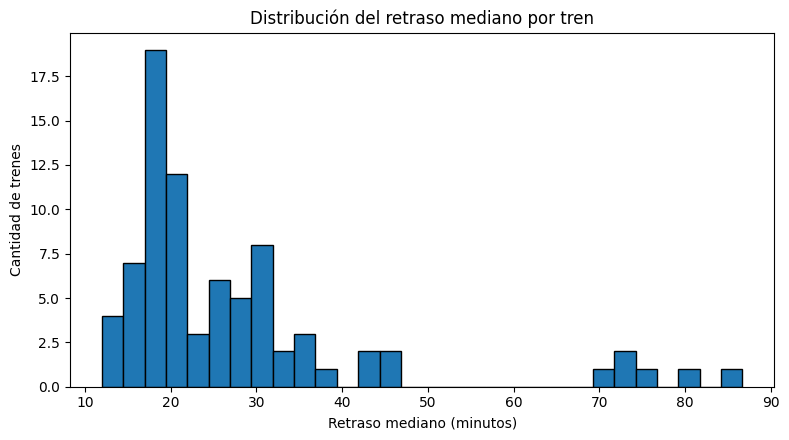

In [8]:
# ============================================================
# 8. DISTRIBUCIÓN DEL RETRASO MEDIANO POR TREN
# ============================================================

plt.figure(figsize=(8, 4.5))
plt.hist(perfil_trenes["retraso_mediano"], bins=30, edgecolor="black")
plt.title("Distribución del retraso mediano por tren")
plt.xlabel("Retraso mediano (minutos)")
plt.ylabel("Cantidad de trenes")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_hist_retraso_mediano.png", dpi=160)
plt.show()


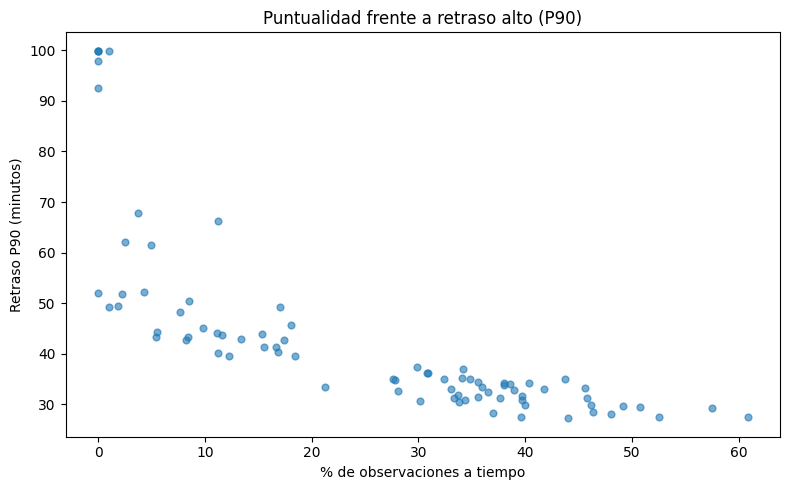

In [9]:
# ============================================================
# 9. PUNTUALIDAD FRENTE A RETRASO ALTO
# ============================================================

plt.figure(figsize=(8, 5))
plt.scatter(
    perfil_trenes["porcentaje_a_tiempo"],
    perfil_trenes["retraso_p90"],
    s=24,
    alpha=0.60
)
plt.title("Puntualidad frente a retraso alto (P90)")
plt.xlabel("% de observaciones a tiempo")
plt.ylabel("Retraso P90 (minutos)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_puntualidad_vs_p90.png", dpi=160)
plt.show()


## 5. Clustering jerárquico aglomerativo

In [10]:
# ============================================================
# 10. PREPARACIÓN DE VARIABLES
# ============================================================

FEATURES_CLUSTER = [
    "retraso_mediano",
    "retraso_promedio",
    "retraso_p90",
    "desviacion_retraso",
    "porcentaje_a_tiempo",
    "porcentaje_retraso_severo",
]

X = perfil_trenes[FEATURES_CLUSTER].copy()

preparador = Pipeline(steps=[
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

X_escalado = preparador.fit_transform(X)

print("Matriz para clustering:", X_escalado.shape)


Matriz para clustering: (80, 6)


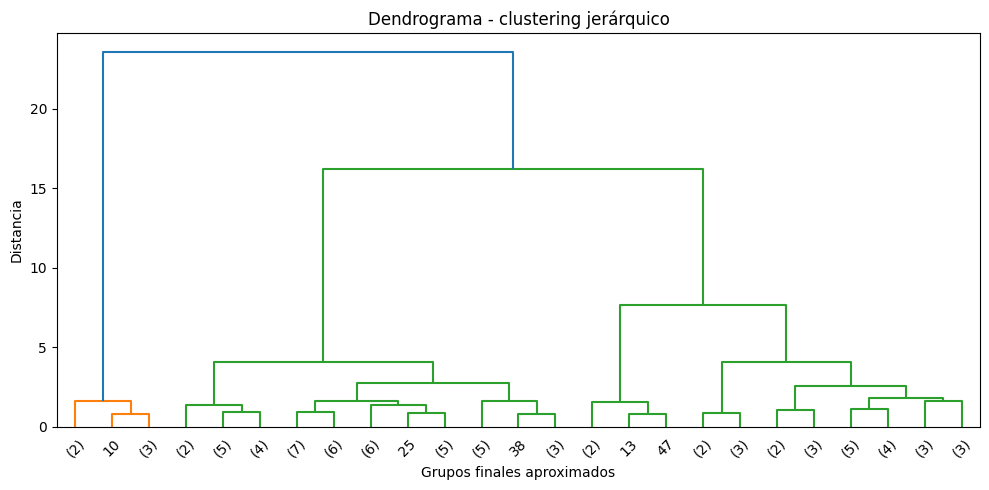

In [11]:
# ============================================================
# 11. DENDROGRAMA
# ============================================================

Z = linkage(X_escalado, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="lastp", p=25, leaf_rotation=45)
plt.title("Dendrograma - clustering jerárquico")
plt.xlabel("Grupos finales aproximados")
plt.ylabel("Distancia")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_dendrograma.png", dpi=160)
plt.show()


,clusters,silhouette
0,2,0.7118
1,3,0.6033
2,4,0.6206
3,5,0.5782
4,6,0.4373


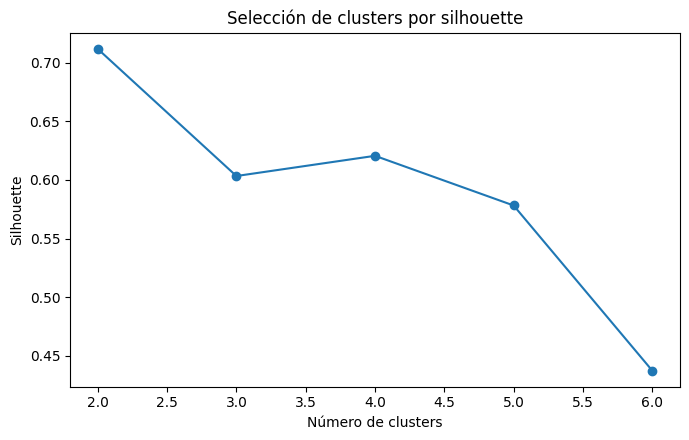

Número de clusters seleccionado: 2


In [12]:
# ============================================================
# 12. SELECCIÓN DEL NÚMERO DE CLUSTERS
# ============================================================

resultados_k = []

for k in range(2, min(7, len(perfil_trenes))):
    modelo_tmp = AgglomerativeClustering(n_clusters=k, linkage="ward")
    etiquetas_tmp = modelo_tmp.fit_predict(X_escalado)
    score = silhouette_score(X_escalado, etiquetas_tmp)
    resultados_k.append({"clusters": k, "silhouette": score})

resultado_k = pd.DataFrame(resultados_k)
MEJOR_K = int(resultado_k.sort_values("silhouette", ascending=False).iloc[0]["clusters"])

display(resultado_k.round(4))

plt.figure(figsize=(7, 4.5))
plt.plot(resultado_k["clusters"], resultado_k["silhouette"], marker="o")
plt.title("Selección de clusters por silhouette")
plt.xlabel("Número de clusters")
plt.ylabel("Silhouette")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_silhouette.png", dpi=160)
plt.show()

print("Número de clusters seleccionado:", MEJOR_K)


In [13]:
# ============================================================
# 13. ENTRENAMIENTO DEL MODELO NO SUPERVISADO
# ============================================================

modelo_cluster = AgglomerativeClustering(n_clusters=MEJOR_K, linkage="ward")
perfil_trenes["cluster"] = modelo_cluster.fit_predict(X_escalado)

conteo_clusters = perfil_trenes["cluster"].value_counts().sort_index()

print("Cantidad de trenes por cluster:")
display(conteo_clusters.to_frame("trenes"))


Cantidad de trenes por cluster:


,trenes
cluster,
0,74
1,6


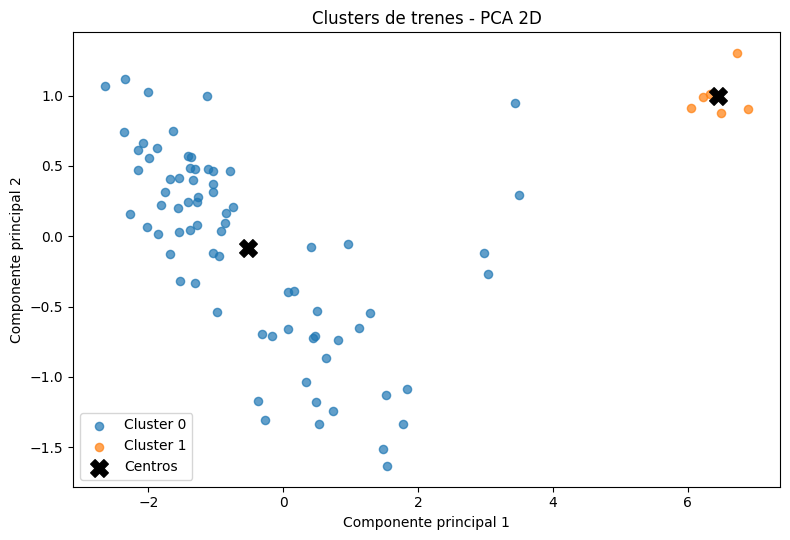

In [14]:
# ============================================================
# 14. VISUALIZACIÓN DE CLUSTERS CON PCA
# ============================================================

pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_escalado)
perfil_trenes["PC1"] = coords[:, 0]
perfil_trenes["PC2"] = coords[:, 1]

plt.figure(figsize=(8, 5.5))
for cluster_id, grupo in perfil_trenes.groupby("cluster"):
    plt.scatter(grupo["PC1"], grupo["PC2"], s=35, alpha=0.70, label=f"Cluster {cluster_id}")

# Centro visual de cada cluster en el plano PCA.
centros = perfil_trenes.groupby("cluster")[["PC1", "PC2"]].mean()
plt.scatter(centros["PC1"], centros["PC2"], s=160, marker="X", color="black", label="Centros")

plt.title("Clusters de trenes - PCA 2D")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_clusters_pca.png", dpi=160)
plt.show()


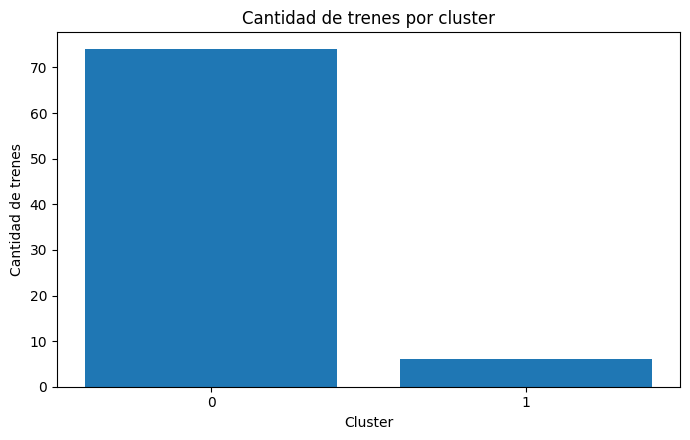

In [15]:
# ============================================================
# 15. TAMAÑO DE LOS CLUSTERS
# ============================================================

plt.figure(figsize=(7, 4.5))
plt.bar(conteo_clusters.index.astype(str), conteo_clusters.values)
plt.title("Cantidad de trenes por cluster")
plt.xlabel("Cluster")
plt.ylabel("Cantidad de trenes")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_tamano_clusters.png", dpi=160)
plt.show()


,retraso_mediano,retraso_promedio,retraso_p90,desviacion_retraso,porcentaje_a_tiempo,porcentaje_retraso_severo,trenes
cluster,,,,,,,
0,23.76,23.85,38.22,11.36,27.21,30.35,74
1,76.01,74.16,98.37,19.12,0.17,97.56,6


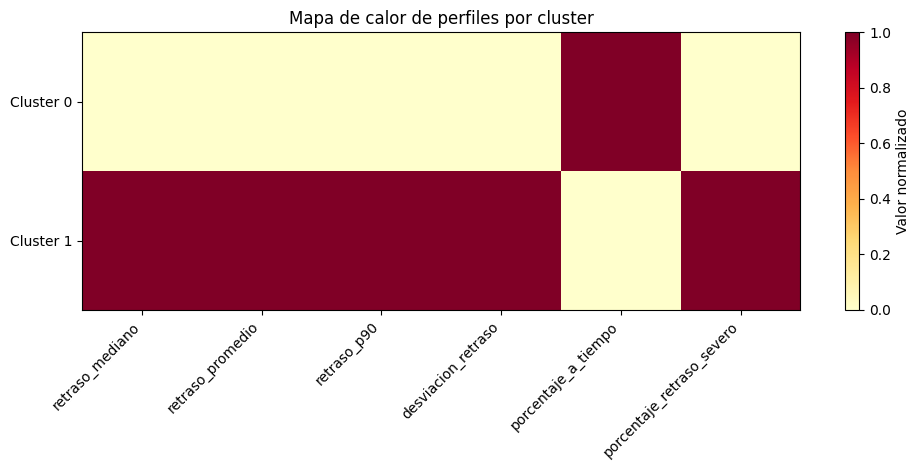

In [16]:
# ============================================================
# 16. PERFIL PROMEDIO DE CADA CLUSTER
# ============================================================

perfiles = perfil_trenes.groupby("cluster")[FEATURES_CLUSTER].mean().round(2)
perfiles["trenes"] = conteo_clusters

display(perfiles)

# Normalización solo para visualizar el mapa de calor.
perfiles_grafica = perfiles.drop(columns=["trenes"])
rango = perfiles_grafica.max() - perfiles_grafica.min()
perfiles_norm = (perfiles_grafica - perfiles_grafica.min()) / rango.replace(0, 1)

plt.figure(figsize=(10, 4.8))
plt.imshow(perfiles_norm, aspect="auto", cmap="YlOrRd")
plt.title("Mapa de calor de perfiles por cluster")
plt.xticks(range(len(FEATURES_CLUSTER)), FEATURES_CLUSTER, rotation=45, ha="right")
plt.yticks(range(len(perfiles_norm.index)), [f"Cluster {i}" for i in perfiles_norm.index])
plt.colorbar(label="Valor normalizado")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_heatmap_perfiles.png", dpi=160)
plt.show()


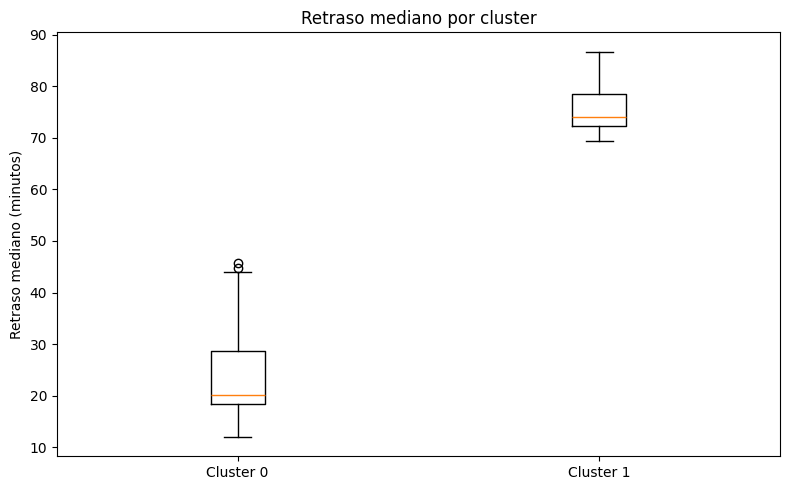

In [17]:
# ============================================================
# 17. BOXPLOT DE RETRASO MEDIANO POR CLUSTER
# ============================================================

datos_box = [
    perfil_trenes.loc[perfil_trenes["cluster"] == c, "retraso_mediano"]
    for c in sorted(perfil_trenes["cluster"].unique())
]

plt.figure(figsize=(8, 5))
plt.boxplot(datos_box, labels=[f"Cluster {c}" for c in sorted(perfil_trenes["cluster"].unique())])
plt.title("Retraso mediano por cluster")
plt.ylabel("Retraso mediano (minutos)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "08_boxplot_retraso.png", dpi=160)
plt.show()


In [18]:
# ============================================================
# 18. PRUEBAS AUTOMÁTICAS
# ============================================================

pruebas = []

def ok(nombre, condicion):
    pruebas.append({"prueba": nombre, "resultado": "OK" if condicion else "FALLA"})
    assert condicion, nombre

ok("Hay trenes suficientes para agrupar", len(perfil_trenes) >= MEJOR_K)
ok("Se usó un único método no supervisado", modelo_cluster.__class__.__name__ == "AgglomerativeClustering")
ok("No se usa variable objetivo supervisada", "is_delayed" not in FEATURES_CLUSTER)
ok("La matriz escalada no tiene nulos", not np.isnan(X_escalado).any())
ok("El número de clusters es mayor que uno", MEJOR_K > 1)
ok("Cada tren tiene cluster asignado", perfil_trenes["cluster"].notna().all())
ok("El silhouette fue calculado", resultado_k["silhouette"].notna().all())
ok("El PCA tiene dos componentes", coords.shape[1] == 2)
ok("El heatmap fue generado", (OUTPUT_DIR / "07_heatmap_perfiles.png").exists())
ok("La gráfica PCA fue generada", (OUTPUT_DIR / "05_clusters_pca.png").exists())
ok("El dendrograma fue generado", (OUTPUT_DIR / "03_dendrograma.png").exists())

resultado_pruebas = pd.DataFrame(pruebas)
display(resultado_pruebas)
print("Pruebas aprobadas:", (resultado_pruebas["resultado"] == "OK").sum(), "/", len(resultado_pruebas))


,prueba,resultado
0,Hay trenes suficientes para agrupar,OK
1,Se usó un único método no supervisado,OK
2,No se usa variable objetivo supervisada,OK
3,La matriz escalada no tiene nulos,OK
4,El número de clusters es mayor que uno,OK
5,Cada tren tiene cluster asignado,OK
6,El silhouette fue calculado,OK
7,El PCA tiene dos componentes,OK
8,El heatmap fue generado,OK
9,La gráfica PCA fue generada,OK


Pruebas aprobadas: 11 / 11


## Conclusión

El clustering jerárquico permitió identificar perfiles de trenes según puntualidad, retrasos severos y comportamiento histórico. El dendrograma y el mapa de calor ayudan a interpretar los grupos sin utilizar etiquetas supervisadas.